# YOLOv8 PPE Detection — Kaggle P100 Notebook

**Environment:** Kaggle GPU P100 (16 GB VRAM)

**Data flow (Kaggle convention):**
- Input dataset lives at `/kaggle/input/<your-dataset-slug>/` — read-only
- All outputs (weights, plots, CSVs) go to `/kaggle/working/` — writable

**How to attach your dataset in Kaggle:**
1. Open the notebook editor → *+ Add data* (right panel)
2. Search for your Roboflow-exported PPE dataset (or upload it as a Kaggle dataset)
3. Note the slug that appears under `/kaggle/input/` and set `DATASET_SLUG` below

No Roboflow download happens at runtime. The dataset is already mounted by Kaggle.

In [ ]:
# Step 1: Verify GPU
!nvidia-smi

In [ ]:
!pip install -q torch==2.5.0 torchvision==0.20.0 torchaudio==2.5.0 --index-url https://download.pytorch.org/whl/cu121 --force-reinstall --quiet 

In [ ]:
!pip install -q ultralytics==8.3.0 fastapi==0.115.0 "uvicorn[standard]==0.30.6" opencv-python==4.10.0.84 python-multipart==0.0.9 numpy==1.26.4 --quiet 

In [ ]:
!pip install -U ultralytics

In [1]:
import torch 

print(f"PyTorch : {torch.version}") 
print(f"CUDA : {torch.version.cuda}") 
print(f"GPU : {torch.cuda.get_device_name(0)}") 
cap = torch.cuda.get_device_capability(0) 
print(f"sm cap : sm_{cap[0]}{cap[1]}") # expect sm_60 
print(f"Ready : {torch.cuda.is_available()}") 

PyTorch : <module 'torch.version' from '/usr/local/lib/python3.12/dist-packages/torch/version.py'>
CUDA : 12.1
GPU : Tesla P100-PCIE-16GB
sm cap : sm_60
Ready : True


In [2]:
from torch.cuda import get_arch_list 
archs = get_arch_list() 
print(f"Compiled archs: {archs}") 
assert any("6" in a for a in archs), "sm_60 still missing — check install" 
print("\n✅ P100 is fully supported by this PyTorch build.")

Compiled archs: ['sm_50', 'sm_60', 'sm_70', 'sm_75', 'sm_80', 'sm_86', 'sm_90']

✅ P100 is fully supported by this PyTorch build.


In [3]:
# Step 3: Imports
import os, sys, json, yaml, shutil
from pathlib import Path
from collections import Counter

import torch
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ultralytics import YOLO

print('PyTorch :', torch.__version__)
print('CUDA    :', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU     :', torch.cuda.get_device_name(0))
    print('VRAM GB :', round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2))

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
PyTorch : 2.5.0+cu121
CUDA    : True
GPU     : Tesla P100-PCIE-16GB
VRAM GB : 17.06


In [4]:
import importlib, sys 

required = { "fastapi": "fastapi", "uvicorn": "uvicorn", "ultralytics": "ultralytics", "cv2": "opencv-python", "numpy": "numpy", "multipart": "python-multipart", } 

all_ok = True 
for module, pkg in required.items(): 
    try: 
        importlib.import_module(module) 
        print(f" ✅ {pkg}") 
    except ImportError: 
        print(f" ❌ {pkg} ← ACTUALLY missing") 
        all_ok = False 

print("\n✅ All good — ignore the resolver warnings above." if all_ok else "\n❌ Re-install the missing ones above.") 

 ✅ fastapi
 ✅ uvicorn
 ✅ ultralytics
 ✅ opencv-python
 ✅ numpy
 ✅ python-multipart

✅ All good — ignore the resolver warnings above.


## Configuration — only cell you need to edit

In [5]:
# ── Paths (Kaggle standard) ───────────────────────────────────────────────────
INPUT_DIR  = Path('/kaggle/input')
WORK_DIR   = Path('/kaggle/working')   # all outputs land here

# Set this to the subfolder name that appears under /kaggle/input/ after adding your dataset
DATASET_SLUG = '/kaggle/input/datasets/tkailashmurali/ppe-poc/ppe-poc'   # <-- change this to your actual slug

DATASET_ROOT = INPUT_DIR / DATASET_SLUG  # read-only source
DATA_YAML    = DATASET_ROOT / 'data.yaml'

# Working directories (writable)
RUNS_DIR     = WORK_DIR / 'runs'
YAML_OUT     = WORK_DIR / 'data_local.yaml'  # patched copy of data.yaml
RUNS_DIR.mkdir(parents=True, exist_ok=True)

# ── Model & training ──────────────────────────────────────────────────────────
MODEL_NAME   = 'yolov8s.pt'  # yolov8m is a strong P100 baseline; use yolov8l.pt if VRAM allows
IMGSZ        = 640
EPOCHS       = 120
PATIENCE     = 40
CLOSE_MOSAIC = 15
WORKERS      = 2
DEVICE       = 0             # GPU 0 = P100 on Kaggle
RUN_NAME     = 'ppe_p100'

## Step 1 — Verify dataset is mounted
This confirms Kaggle has correctly mounted the dataset and that `data.yaml` exists.

In [6]:
assert DATASET_ROOT.exists(), (
    f"Dataset not found at {DATASET_ROOT}.\n"
    f"Available inputs: {[p.name for p in INPUT_DIR.iterdir() if p.is_dir()]}"
)
assert DATA_YAML.exists(), f'data.yaml not found inside {DATASET_ROOT}'

print('Dataset root :', DATASET_ROOT)
print('data.yaml    :', DATA_YAML)
print('Splits found :', [p.name for p in DATASET_ROOT.iterdir() if p.is_dir()])

Dataset root : /kaggle/input/datasets/tkailashmurali/ppe-poc/ppe-poc
data.yaml    : /kaggle/input/datasets/tkailashmurali/ppe-poc/ppe-poc/data.yaml
Splits found : ['valid', 'test', 'train']


## Step 2 — Patch `data.yaml` for Kaggle
Roboflow exports data.yaml with relative or original-machine paths. Ultralytics needs `path:` to point to the actual dataset root at `/kaggle/input/`. We write a patched copy to `/kaggle/working/` and train from that.

In [7]:
with open(DATA_YAML, 'r') as f:
    cfg = yaml.safe_load(f)

print('Original data.yaml:\n', json.dumps(cfg, indent=2))

Original data.yaml:
 {
  "train": "../train/images",
  "val": "../valid/images",
  "test": "../test/images",
  "nc": 11,
  "names": [
    "boots",
    "glasses",
    "gloves",
    "helmet",
    "no boots",
    "no glasses",
    "no gloves",
    "no helmet",
    "no vest",
    "person",
    "vest"
  ],
  "roboflow": {
    "workspace": "kailash-murali-t",
    "project": "ppe-cpxsz-9kuqb",
    "version": "dataset",
    "license": "CC BY 4.0",
    "url": "https://universe.roboflow.com/kailash-murali-t/ppe-cpxsz-9kuqb/dataset/dataset"
  }
}


In [8]:
# Resolve actual split image directories regardless of Roboflow naming (valid vs val)
def find_images_dir(root: Path, key: str):
    """Return the images directory for a split, tolerating 'valid' vs 'val'."""
    aliases = [key, 'valid' if key == 'val' else 'val']
    for alias in aliases:
        candidate = root / alias / 'images'
        if candidate.exists():
            return str(candidate)
        candidate = root / alias
        if candidate.exists():
            return str(candidate)
    return None

train_dir = find_images_dir(DATASET_ROOT, 'train')
val_dir   = find_images_dir(DATASET_ROOT, 'val')
test_dir  = find_images_dir(DATASET_ROOT, 'test')

assert train_dir, f'Train split images not found under {DATASET_ROOT}'
assert val_dir,   f'Val/Valid split images not found under {DATASET_ROOT}'

print('train :', train_dir)
print('val   :', val_dir)
print('test  :', test_dir)

train : /kaggle/input/datasets/tkailashmurali/ppe-poc/ppe-poc/train/images
val   : /kaggle/input/datasets/tkailashmurali/ppe-poc/ppe-poc/valid/images
test  : /kaggle/input/datasets/tkailashmurali/ppe-poc/ppe-poc/test/images


In [9]:
# Write the patched YAML to /kaggle/working/ (writable)
patched = {
    'train': train_dir,
    'val'  : val_dir,
    'nc'   : cfg.get('nc', len(cfg['names'])),
    'names': cfg['names']
}
if test_dir:
    patched['test'] = test_dir

with open(YAML_OUT, 'w') as f:
    yaml.dump(patched, f, default_flow_style=False, allow_unicode=True)

print('Patched YAML written to:', YAML_OUT)
print(YAML_OUT.read_text())

Patched YAML written to: /kaggle/working/data_local.yaml
names:
- boots
- glasses
- gloves
- helmet
- no boots
- no glasses
- no gloves
- no helmet
- no vest
- person
- vest
nc: 11
test: /kaggle/input/datasets/tkailashmurali/ppe-poc/ppe-poc/test/images
train: /kaggle/input/datasets/tkailashmurali/ppe-poc/ppe-poc/train/images
val: /kaggle/input/datasets/tkailashmurali/ppe-poc/ppe-poc/valid/images



## Step 3 — Inspect class distribution
Always inspect before training. Convergence problems are usually data problems first.

In [10]:
class_names = cfg['names'] if isinstance(cfg['names'], list) else list(cfg['names'].values())
num_classes  = len(class_names)

def count_split(images_dir_str, split_name):
    images_dir = Path(images_dir_str)
    labels_dir = images_dir.parent / 'labels'
    image_files = [p for p in images_dir.glob('*') if p.suffix.lower() in {'.jpg','.jpeg','.png','.bmp','.webp'}]
    label_files = list(labels_dir.glob('*.txt')) if labels_dir.exists() else []
    cls_counter = Counter()
    empty = 0
    for lf in label_files:
        txt = lf.read_text().strip()
        if not txt:
            empty += 1
            continue
        for line in txt.splitlines():
            parts = line.strip().split()
            if len(parts) >= 5:
                cls_counter[int(float(parts[0]))] += 1
    return dict(split=split_name, images=len(image_files), labels=len(label_files),
                empty_labels=empty, boxes=sum(cls_counter.values()), class_counter=cls_counter)

split_sources = [('train', train_dir), ('val', val_dir)]
if test_dir: split_sources.append(('test', test_dir))

stats = [count_split(d, s) for s, d in split_sources]
summary = pd.DataFrame([{k:v for k,v in s.items() if k != 'class_counter'} for s in stats])
display(summary)

,split,images,labels,empty_labels,boxes
0,train,11355,11355,0,38338
1,val,3246,3246,0,10980
2,test,1622,1622,0,5574


,class_id,class_name,boxes
9,9,person,9367
6,6,no gloves,6790
3,3,helmet,6207
2,2,gloves,5919
4,4,no boots,5511
0,0,boots,5072
8,8,no vest,3732
7,7,no helmet,3373
10,10,vest,3211
5,5,no glasses,3133


Imbalance ratio (max/min boxes): 3.6


/tmp/ipykernel_165/4010475360.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=class_df, x='class_name', y='boxes', palette='viridis', ax=ax)
/tmp/ipykernel_165/4010475360.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')


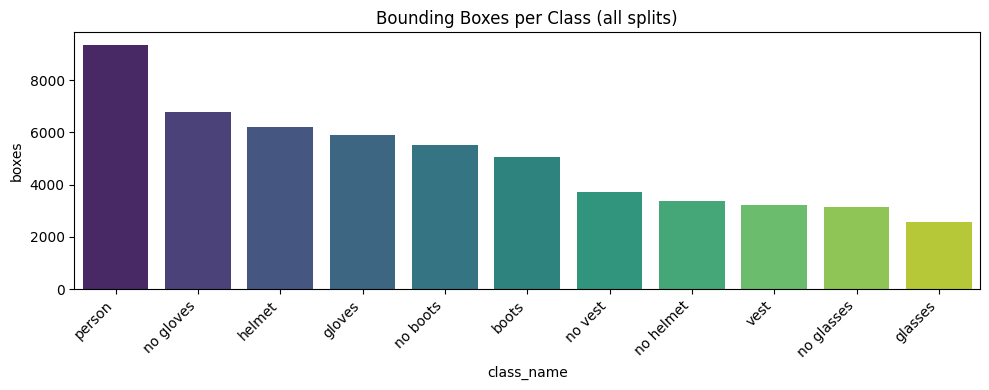

Saved: /kaggle/working/class_distribution.png


In [11]:
class_totals = Counter()
for s in stats: class_totals.update(s['class_counter'])

class_df = pd.DataFrame({
    'class_id'  : list(range(num_classes)),
    'class_name': class_names,
    'boxes'     : [class_totals.get(i, 0) for i in range(num_classes)]
}).sort_values('boxes', ascending=False)

display(class_df)

imbalance_ratio = class_df['boxes'].max() / max(1, class_df['boxes'].min())
print(f'Imbalance ratio (max/min boxes): {imbalance_ratio:.1f}')

fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(data=class_df, x='class_name', y='boxes', palette='viridis', ax=ax)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
ax.set_title('Bounding Boxes per Class (all splits)')
plt.tight_layout()
plt.savefig(WORK_DIR / 'class_distribution.png', dpi=150)
plt.show()
print('Saved:', WORK_DIR / 'class_distribution.png')

## Step 4 — Training

**Key P100 choices:**
- `project` and `name` point inside `/kaggle/working/` so all weights and plots are saved where Kaggle can read them as outputs
- `batch=-1` lets Ultralytics auto-fit to P100 VRAM (16 GB)
- `amp=True` uses FP16 mixed precision — P100 supports this well
- `cache='disk'` avoids re-reading from the read-only input directory on every epoch
- `cos_lr=True` gives a smooth learning-rate schedule that helps reach a clean minimum
- `close_mosaic=15` disables mosaic for the last 15 epochs so the model stabilises cleanly

In [12]:
# Auto-set cls_pw based on imbalance ratio
cls_pw = 0.25 if imbalance_ratio >= 4 else 0.0
print(f'cls_pw set to {cls_pw} (imbalance_ratio={imbalance_ratio:.1f})')

train_args = dict(
    data        = str(YAML_OUT),
    epochs      = EPOCHS,
    imgsz       = IMGSZ,
    batch       = -1,           # auto-fit to P100 VRAM
    device      = DEVICE,       # 0 = P100
    workers     = WORKERS,
    pretrained  = True,
    optimizer   = 'auto',
    cos_lr      = True,
    patience    = PATIENCE,
    close_mosaic= CLOSE_MOSAIC,
    amp         = True,
    cache       = 'disk',       # cache to /kaggle/working via tmp; avoids re-reading input
    rect        = False,
    val         = True,
    plots       = True,
    save        = True,
    project     = str(RUNS_DIR),# /kaggle/working/runs
    name        = RUN_NAME,
    exist_ok    = True,
    seed        = 42,
    deterministic=True,
    cls_pw      = cls_pw,
    # Augmentation
    hsv_h       = 0.015,
    hsv_s       = 0.7,
    hsv_v       = 0.4,
    degrees     = 5.0,
    translate   = 0.08,
    scale       = 0.4,
    shear       = 0.0,
    perspective = 0.0,
    flipud      = 0.0,
    fliplr      = 0.5,
    mosaic      = 1.0,
    mixup       = 0.05
)

cls_pw set to 0.0 (imbalance_ratio=3.6)


In [ ]:
model   = YOLO(MODEL_NAME)
results = model.train(**train_args)

In [1]:
run_dir   = RUNS_DIR / RUN_NAME
best_path = run_dir / 'weights' / 'best.pt'
last_path = run_dir / 'weights' / 'last.pt'
print('Run dir  :', run_dir)
print('best.pt  :', best_path, '| exists:', best_path.exists())
print('last.pt  :', last_path, '| exists:', last_path.exists())

NameError: name 'RUNS_DIR' is not defined

## Step 5 — Validate best checkpoint
Always validate from `best.pt`, not `last.pt`. The model at best validation mAP is the one worth deploying.

In [ ]:
best_model  = YOLO(str(best_path))
val_metrics = best_model.val(data=str(YAML_OUT), split='val', imgsz=IMGSZ, device=DEVICE, plots=True)
print(val_metrics)

In [ ]:
test_metrics = None
if test_dir:
    test_metrics = best_model.val(data=str(YAML_OUT), split='test', imgsz=IMGSZ, device=DEVICE, plots=True)
    print(test_metrics)
else:
    print('No test split found; skipping test evaluation.')

## Step 6 — Training curves
The curves tell the story of convergence. If train loss improves but val stalls, that's overfitting. If both stall early, that's underfitting or a data issue.

In [ ]:
results_csv = run_dir / 'results.csv'
hist = pd.read_csv(results_csv)
hist.columns = hist.columns.str.strip()
display(hist.tail())

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
pairs = [
    ('train/box_loss'      , 'val/box_loss'       ),
    ('train/cls_loss'      , 'val/cls_loss'       ),
    ('metrics/precision(B)', 'metrics/recall(B)'  ),
    ('metrics/mAP50(B)'   , 'metrics/mAP50-95(B)'),
]
for ax, (a, b) in zip(axes.flat, pairs):
    if a in hist.columns: ax.plot(hist[a], label=a.split('/')[-1])
    if b in hist.columns: ax.plot(hist[b], label=b.split('/')[-1])
    ax.legend()
    ax.set_title(f'{a.split("/")[-1]} vs {b.split("/")[-1]}')
    ax.grid(True, alpha=0.3)
plt.suptitle(f'Training history — {RUN_NAME}', fontsize=13)
plt.tight_layout()
fig.savefig(WORK_DIR / 'training_curves.png', dpi=150)
plt.show()
print('Saved:', WORK_DIR / 'training_curves.png')

## Step 7 — Inference sanity check
Predicted boxes on a sample of unseen images. If boxes look wrong visually despite decent metrics, it usually means a label quality issue.

In [ ]:
sample_src = test_dir if test_dir else val_dir
best_model.predict(
    source  = sample_src,
    imgsz   = IMGSZ,
    conf    = 0.25,
    device  = DEVICE,
    save    = True,
    project = str(RUNS_DIR),
    name    = f'{RUN_NAME}_preds',
    exist_ok= True
)
print('Predictions saved to:', RUNS_DIR / f'{RUN_NAME}_preds')

## Step 8 — Export and copy to /kaggle/working/
ONNX export is useful for deployment flexibility outside PyTorch. Weights are also copied explicitly to `/kaggle/working/` so they appear as Kaggle output files.

In [ ]:
best_model.export(format='onnx', imgsz=IMGSZ, half=False, dynamic=True)
onnx_src = best_path.with_suffix('.onnx')
if onnx_src.exists():
    shutil.copy(onnx_src, WORK_DIR / f'{RUN_NAME}_best.onnx')
    print('ONNX saved to:', WORK_DIR / f'{RUN_NAME}_best.onnx')

In [ ]:
# Copy weights to /kaggle/working/ root for easy access as output files
shutil.copy(best_path, WORK_DIR / f'{RUN_NAME}_best.pt')
shutil.copy(last_path, WORK_DIR / f'{RUN_NAME}_last.pt')
print('Weights saved to /kaggle/working/')
print([p.name for p in WORK_DIR.glob('*.pt')])

## Step 9 — Resume training (if interrupted)
Kaggle sessions can time out. Use this cell only if you want to resume a previously interrupted run.

In [13]:
# Uncomment and run if the session was interrupted:
resumed = YOLO("/kaggle/working/runs/ppe_p100_boots_gloves_fix/weights/last.pt")
resumed.train(resume=True)

Ultralytics 8.4.71 🚀 Python-3.12.13 torch-2.5.0+cu121 CUDA:0 (Tesla P100-PCIE-16GB, 16269MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=8.0, cache=disk, cfg=None, classes=None, close_mosaic=10, cls=1.7, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/data_local.yaml, degrees=3.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=768, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.0004, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/kaggle/working/runs/ppe_p100_boots_gloves_fix/weights/last.pt, momentum=0.937, mosaic=0.35, multi_scale=0.0, name=ppe_p100_boots_gloves_fix, nbs=64, nms=Fa

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7d8f544c5a60>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.

In [ ]:
train_args.pop("cls_pw", None)

train_args.update({
    "pretrained": False,
    "epochs": 60,
    "imgsz": 768,
    "optimizer": "AdamW",
    "lr0": 0.0004,
    "lrf": 0.01,
    "weight_decay": 0.0007,

    "box": 8.0,
    "cls": 1.7,
    "dfl": 1.5,

    "mosaic": 0.35,
    "mixup": 0.0,
    "scale": 0.25,
    "degrees": 3.0,
    "translate": 0.05,

    "close_mosaic": 10,
    "name": RUN_NAME + "_boots_gloves_fix",
    "save": True,
})

model = YOLO("/kaggle/working/runs/ppe_p100/weights/best.pt")
results = model.train(**train_args)

## P100 Tuning Playbook

Build floors in order — don't skip to advanced changes before the baseline is solid:

| Step | Condition | Action |
|------|-----------|--------|
| 1 | OOM error | Reduce `imgsz` to 512 before anything else |
| 2 | Baseline stable | Try `yolov8l.pt` — P100 has room for it |
| 3 | Small PPE items missed | Try `imgsz=768` after a solid 640 run |
| 4 | val lags behind train | Reduce `mixup`, `degrees`, `scale` slightly |
| 5 | One class never improves | Check label quality + raise `cls_pw` to 0.5 |
| 6 | All metrics plateau early | Increase `epochs`, lower `lr0` to 0.005 |

**Useful Kaggle-specific tips:**
- Save `best.pt` to the working directory (already done above) so it persists as an output even if the session resets.
- Use `cache='disk'` not `cache=True` (RAM cache) since Kaggle RAM is limited; disk cache writes to `/kaggle/working/` temp space.
- Kaggle GPU sessions expire after 9 hours; if training is longer, use the resume cell above after a fresh session restart.